# Univariate financial ratios and observed defaults
Inspired by Moody's RiskCalc, Section IV (pp. 27–31): rank observations by ratio, form up to 50 groups, and smooth observed default frequency. This is descriptive EDA, not the proprietary RiskCalc transformation or a fitted PD model.

Default labels use the existing 12-month window. By default this uses round 3 training firm-years (2007–2009); the same company can contribute multiple observations. Do not use later test years for feature selection. Ratios are computed after the existing training-only imputation, before VIF and normalization. Imputed values and zero-denominator conventions influence the curves.

In [10]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/feature_schema.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from finance_project.data_processing.preprocess import PreprocessingConfig, _missing, _build_features, clean_and_impute, _oof_target_encode, _region

ROUND = '03'  # training anchors only; change for another round
N_BINS = 50
SMOOTH_WINDOW = 5  # centered rolling window, weighted by bin counts
ZOOM_Y_MAX = 0.03  # 3% observed default rate; change as needed
round_dir = ROOT / 'data/processed/walk_forward_temporal' / f'round_{ROUND}'
train = pd.read_csv(round_dir / 'train.csv', low_memory=False)
history = pd.read_csv(round_dir / 'history.csv', low_memory=False)
config = PreprocessingConfig(feature_mode='firm_year')
medians = _missing['sector_medians'](train)
features = _build_features(train, history, medians, config)
clean = clean_and_impute(train, medians, config)
raw_needed = ['asst_tot', 'eqty_tot', 'inc_extraord', 'debt_st', 'debt_lt', 'asst_intang_fixed', 'AR', 'COGS', 'AP_st', 'taxes', 'inc_financing', 'rev_operating']
# Feature generation retains engineered values; attach imputed raw inputs for new ratios.
features = features.merge(clean[['id', 'fs_year'] + [c for c in raw_needed if c not in features]], on=['id', 'fs_year'], validate='one_to_one')
schema = json.loads((ROOT / 'config/feature_schema_historical_v1_1.json').read_text())
active_schema = json.loads((ROOT / 'config/feature_schema.json').read_text())
selected = set(json.loads((ROOT / 'config/vif_selected_features.json').read_text())['selected_features'])
# Recreate selected training-only categorical and out-of-fold encoded features.
if 'ateco_sector_te' in selected:
    features['ateco_sector_te'] = _oof_target_encode(features, config)[0]
for name in sorted(selected):
    if name.startswith('legal_'):
        features[name] = features[config.legal_column].fillna('Unknown').astype(str).eq(name[6:]).astype(int)
    elif name.startswith('city_'):
        features[name] = _region(features['HQ_city']).eq(name[5:]).astype(int)
def ratio(num, den):
    return num.div(den.where(den != 0)).replace([np.inf, -np.inf], np.nan)

# Explicit candidate formulas; denominators of zero remain missing.
f = features
f['net_income_to_assets'] = ratio(f.profit, f.asst_tot)
f['net_income_less_extraordinary_to_assets'] = ratio(f.profit - f.inc_extraord, f.asst_tot)
f['return_on_equity'] = ratio(f.profit, f.eqty_tot)
f['liabilities_to_assets'] = ratio(f.asst_tot - f.eqty_tot, f.asst_tot)
f['total_debt_to_assets'] = ratio(f.debt_st + f.debt_lt, f.asst_tot)
f['liabilities_to_tangible_assets'] = ratio(f.asst_tot - f.eqty_tot, f.asst_tot - f.asst_intang_fixed)
f['short_to_long_term_debt'] = ratio(f.debt_st, f.debt_lt)
f['receivables_to_cogs'] = ratio(f.AR, f.COGS)
f['payables_to_cogs'] = ratio(f.AP_st, f.COGS)
f['tax_ratio'] = ratio(f.taxes, f.asst_tot)
f['financing_income_ratio'] = ratio(f.inc_financing, f.asst_tot)
# Only consecutive records in the training anchors count as prior-year data.
order = f.sort_values(['id', 'fs_year']).copy()
previous_year = order.groupby('id')['fs_year'].shift()
previous_revenue = order.groupby('id')['rev_operating'].shift()
order['annual_sales_growth'] = ratio(order.rev_operating, previous_revenue).sub(1).where(order.fs_year - previous_year == 1)
f['annual_sales_growth'] = order['annual_sales_growth'].reindex(f.index)
previous_ar = order.groupby('id')['AR'].shift()
consecutive = order.fs_year - previous_year == 1
average_ar = (order.AR + previous_ar) / 2
turnover = ratio(order.rev_operating, average_ar.where(average_ar > 0)).where(consecutive)
prior_turnover = turnover.groupby(order.id).shift()
order['change_in_ar_turnover'] = (turnover - prior_turnover).where(consecutive)
f['change_in_ar_turnover'] = order['change_in_ar_turnover'].reindex(f.index)
group_names = ['business_structural', 'leverage_capital_structure', 'liquidity_activity', 'profitability_growth', 'coverage_cash_flow']
numeric = set(active_schema['period_numeric_features']) | set(schema['period_numeric_features']) | {'ateco_sector_te'}
groups = {k: [x for x in dict.fromkeys(schema['feature_groups'][k] + active_schema['feature_groups'][k]) if x in selected and x in numeric] for k in group_names}
print('Training firm-years:', len(features), '| observed default rate:', f'{features.label.mean():.2%}')
print('Ratio groups:', groups)

Training firm-years: 476183 | observed default rate: 1.24%
Ratio groups: {'business_structural': ['ateco_sector_te', 'size'], 'leverage_capital_structure': ['equity_ratio', 'st_debt_share', 'lt_debt_to_capital', 'bank_debt_conc', 'cur_asst_ratio', 'tangible_asset_ratio', 'debt_to_eqty'], 'liquidity_activity': ['cash_ratio', 'AR_ratio', 'payables_ratio', 'wc_ratio', 'cur_debt_ratio', 'quick_ratio', 'asset_turnover'], 'profitability_growth': ['roa', 'op_margin', 'net_prof_margin', 'roe', 'profit', 'ebitda', 'COGS'], 'coverage_cash_flow': ['int_coverage', 'financing_expense_ratio', 'cash_to_financing_exp_ratio', 'ebitda_to_debt', 'operating_cash_flow_ratio', 'exp_financing', 'operating_cash_flow_margin', 'cash_interest_coverage', 'operating_cash_flow_to_debt']}


## Default-frequency curves
Equal-frequency bins are formed from actual feature values; duplicate quantile edges are merged to avoid splitting identical values. Each line has its own percentile ranking and nonmissing sample. Smoothing is a count-weighted five-bin rolling average, a transparent approximation rather than Moody's Hodrick–Prescott filter. Tables retain bin-level Wilson intervals, which assume independent firm-years. Candidates and formulas are documented in the historical schema; existing pipeline features retain current definitions and zero handling.

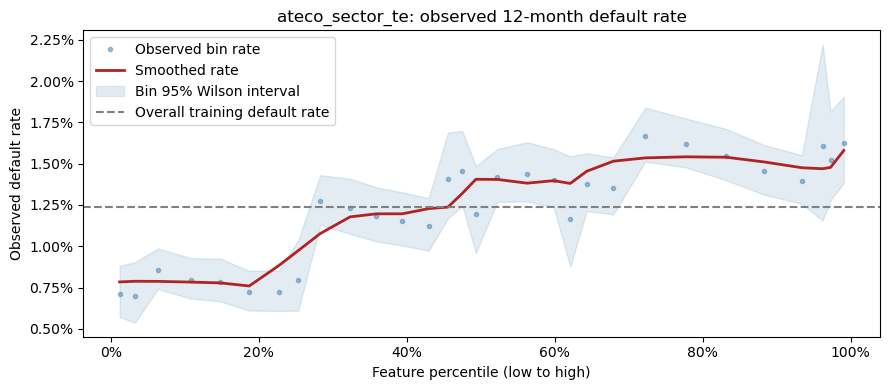

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,11535,82,0.0056,0.0064,0.0063,0.0071,0.0121,0.0078,0.0057,0.0088
1,8034,56,0.0064,0.0065,0.0065,0.0070,0.0327,0.0079,0.0054,0.0090
2,21737,186,0.0066,0.0076,0.0076,0.0086,0.0639,0.0079,0.0074,0.0099
3,20326,162,0.0076,0.0078,0.0078,0.0080,0.1081,0.0078,0.0068,0.0093
4,17953,141,0.0078,0.0078,0.0078,0.0079,0.1483,0.0078,0.0067,0.0093
5,19129,138,0.0079,0.0079,0.0079,0.0072,0.1872,0.0076,0.0061,0.0085
6,18591,134,0.0080,0.0080,0.0080,0.0072,0.2268,0.0088,0.0061,0.0085
7,6782,54,0.0080,0.0097,0.0083,0.0080,0.2535,0.0097,0.0061,0.0104
8,21542,274,0.0097,0.0117,0.0117,0.0127,0.2832,0.0108,0.0113,0.0143
9,16812,207,0.0118,0.0121,0.0121,0.0123,0.3235,0.0118,0.0108,0.0141


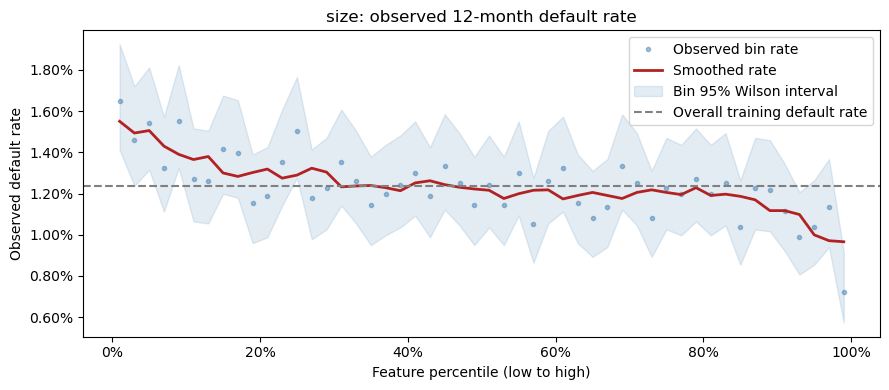

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,157,14.2210,14.2481,14.2343,0.0165,0.01,0.0155,0.0141,0.0192
1,9524,139,14.2482,14.2756,14.2616,0.0146,0.03,0.0149,0.0124,0.0172
2,9523,147,14.2756,14.3036,14.2897,0.0154,0.05,0.0151,0.0131,0.0181
3,9524,126,14.3036,14.3320,14.3177,0.0132,0.07,0.0143,0.0111,0.0157
4,9524,148,14.3320,14.3605,14.3461,0.0155,0.09,0.0139,0.0132,0.0182
5,9523,121,14.3605,14.3897,14.3750,0.0127,0.11,0.0137,0.0106,0.0152
6,9524,120,14.3897,14.4189,14.4042,0.0126,0.13,0.0138,0.0105,0.0150
7,9524,135,14.4189,14.4487,14.4339,0.0142,0.15,0.0130,0.0120,0.0168
8,9523,133,14.4488,14.4789,14.4638,0.0140,0.17,0.0128,0.0118,0.0165
9,9524,110,14.4789,14.5100,14.4944,0.0115,0.19,0.0130,0.0096,0.0139


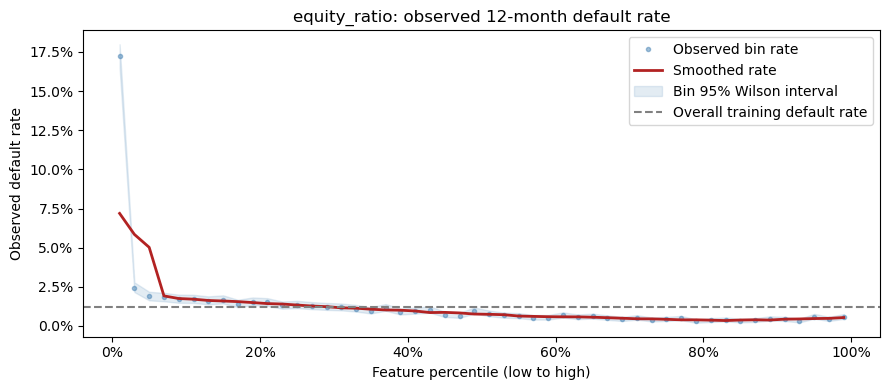

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,1640,-65.8753,-0.0229,-0.0846,0.1722,0.01,0.0719,0.1647,0.1799
1,9524,234,-0.0229,0.0006,-0.0054,0.0246,0.03,0.0585,0.0216,0.0279
2,9523,180,0.0006,0.0044,0.0027,0.0189,0.05,0.0502,0.0164,0.0218
3,9524,174,0.0044,0.0077,0.0060,0.0183,0.07,0.0192,0.0158,0.0212
4,9524,164,0.0077,0.0117,0.0096,0.0172,0.09,0.0175,0.0148,0.0200
5,9523,163,0.0117,0.0161,0.0138,0.0171,0.11,0.0171,0.0147,0.0199
6,9524,154,0.0161,0.0210,0.0185,0.0162,0.13,0.0163,0.0138,0.0189
7,9524,160,0.0210,0.0263,0.0236,0.0168,0.15,0.0160,0.0144,0.0196
8,9523,135,0.0263,0.0318,0.0290,0.0142,0.17,0.0156,0.0120,0.0168
9,9524,148,0.0318,0.0377,0.0347,0.0155,0.19,0.0150,0.0132,0.0182


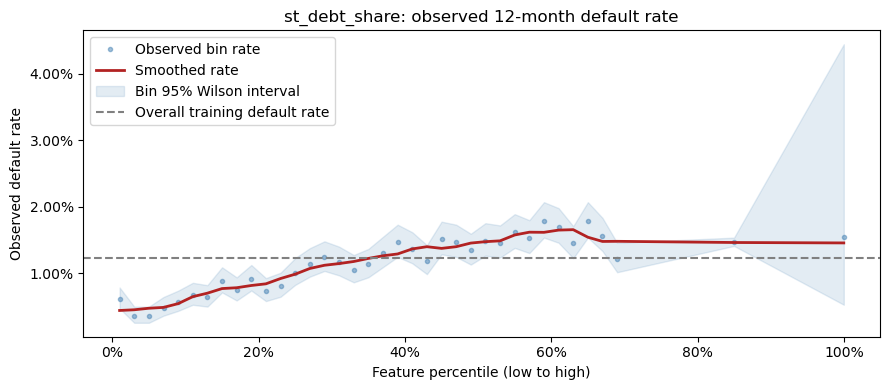

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,58,-5.8305,0.0154,0.0045,0.0061,0.0100,0.0044,0.0047,0.0079
1,9524,34,0.0154,0.0464,0.0301,0.0036,0.0300,0.0045,0.0026,0.0050
2,9523,34,0.0464,0.0813,0.0633,0.0036,0.0500,0.0047,0.0026,0.0050
3,9524,46,0.0813,0.1210,0.1004,0.0048,0.0700,0.0049,0.0036,0.0064
4,9524,54,0.1210,0.1637,0.1421,0.0057,0.0900,0.0054,0.0043,0.0074
5,9523,64,0.1637,0.2074,0.1857,0.0067,0.1100,0.0065,0.0053,0.0086
6,9524,61,0.2074,0.2510,0.2290,0.0064,0.1300,0.0070,0.0050,0.0082
7,9524,84,0.2510,0.2960,0.2734,0.0088,0.1500,0.0077,0.0071,0.0109
8,9523,71,0.2960,0.3411,0.3185,0.0075,0.1700,0.0078,0.0059,0.0094
9,9524,87,0.3411,0.3850,0.3632,0.0091,0.1900,0.0082,0.0074,0.0113


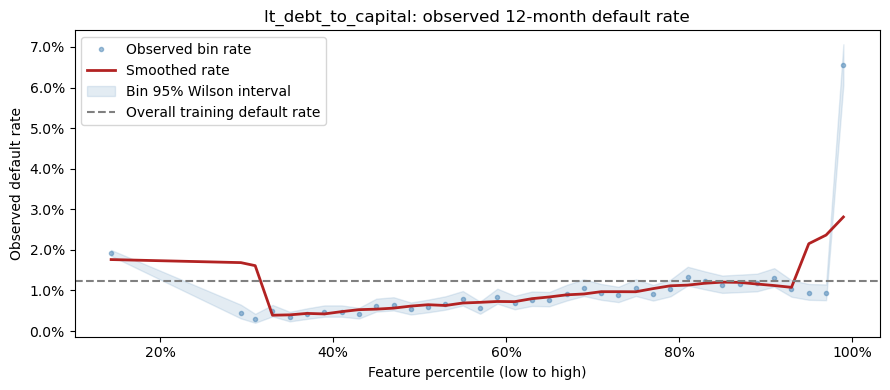

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,136630,2628,-2861.9229,0.0000,0.0000,0.0192,0.1435,0.0176,0.0185,0.0200
1,6225,28,0.0000,0.0035,0.0013,0.0045,0.2935,0.0169,0.0031,0.0065
2,9524,28,0.0035,0.0136,0.0077,0.0029,0.3100,0.0161,0.0020,0.0042
3,9523,46,0.0136,0.0324,0.0215,0.0048,0.3300,0.0039,0.0036,0.0064
4,9524,32,0.0324,0.0573,0.0442,0.0034,0.3500,0.0040,0.0024,0.0047
5,9524,39,0.0573,0.0850,0.0709,0.0041,0.3700,0.0043,0.0030,0.0056
6,9523,45,0.0850,0.1142,0.0994,0.0047,0.3900,0.0042,0.0035,0.0063
7,9524,45,0.1142,0.1446,0.1291,0.0047,0.4100,0.0048,0.0035,0.0063
8,9524,40,0.1446,0.1755,0.1598,0.0042,0.4300,0.0053,0.0031,0.0057
9,9523,59,0.1755,0.2074,0.1913,0.0062,0.4500,0.0054,0.0048,0.0080


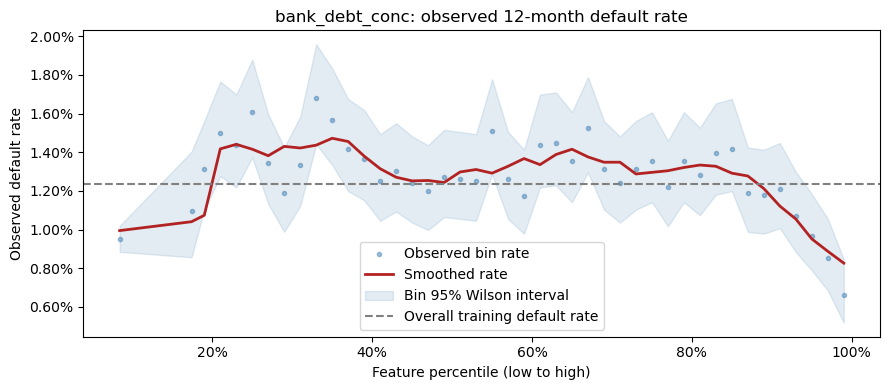

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,80059,760,-174731.0970,0.0000,0.0000,0.0095,0.0841,0.0099,0.0088,0.0102
1,5654,62,0.0000,0.0001,0.0000,0.0110,0.1741,0.0104,0.0086,0.0140
2,9524,125,0.0001,0.0028,0.0007,0.0131,0.1900,0.0107,0.0110,0.0156
3,9524,143,0.0028,0.0167,0.0093,0.0150,0.2100,0.0142,0.0128,0.0177
4,9523,137,0.0167,0.0299,0.0222,0.0144,0.2300,0.0144,0.0122,0.0170
5,9524,153,0.0299,0.0472,0.0393,0.0161,0.2500,0.0142,0.0137,0.0188
6,9523,128,0.0472,0.0601,0.0522,0.0134,0.2700,0.0138,0.0113,0.0160
7,9524,113,0.0601,0.0753,0.0668,0.0119,0.2900,0.0143,0.0099,0.0142
8,9524,127,0.0753,0.0895,0.0845,0.0133,0.3100,0.0142,0.0112,0.0158
9,9523,160,0.0895,0.1047,0.0967,0.0168,0.3300,0.0144,0.0144,0.0196


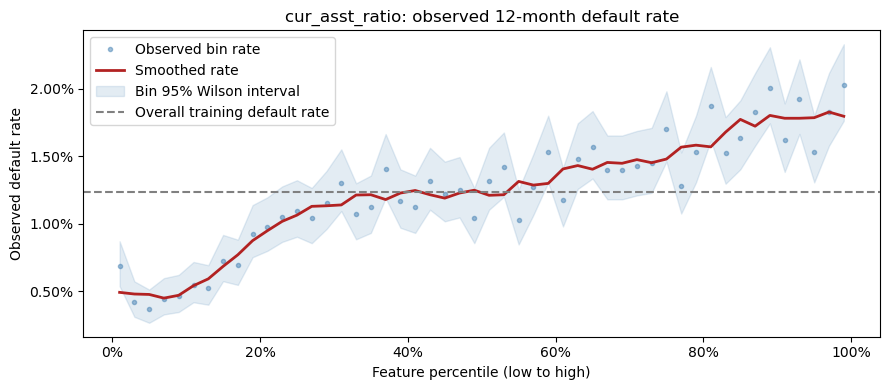

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,65,0.0000,0.0107,0.0049,0.0068,0.01,0.0049,0.0054,0.0087
1,9524,40,0.0107,0.0234,0.0169,0.0042,0.03,0.0048,0.0031,0.0057
2,9523,35,0.0234,0.0381,0.0303,0.0037,0.05,0.0047,0.0026,0.0051
3,9524,42,0.0381,0.0563,0.0468,0.0044,0.07,0.0045,0.0033,0.0060
4,9524,44,0.0563,0.0771,0.0663,0.0046,0.09,0.0047,0.0034,0.0062
5,9523,52,0.0771,0.1014,0.0888,0.0055,0.11,0.0054,0.0042,0.0072
6,9524,50,0.1014,0.1302,0.1152,0.0052,0.13,0.0059,0.0040,0.0069
7,9524,69,0.1302,0.1628,0.1465,0.0072,0.15,0.0068,0.0057,0.0092
8,9523,66,0.1628,0.1992,0.1799,0.0069,0.17,0.0077,0.0055,0.0088
9,9524,88,0.1992,0.2396,0.2192,0.0092,0.19,0.0087,0.0075,0.0114


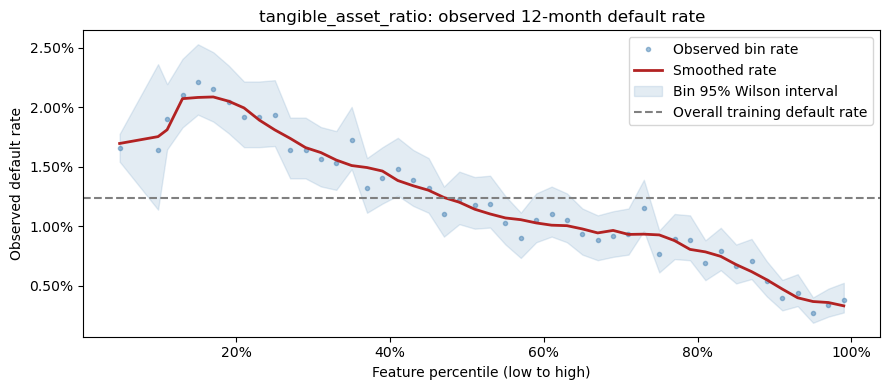

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,45914,760,-0.5029,0.0000,0.0000,0.0166,0.0482,0.0170,0.0154,0.0178
1,1705,28,0.0000,0.0001,0.0000,0.0164,0.0982,0.0175,0.0114,0.0236
2,9523,181,0.0001,0.0007,0.0003,0.0190,0.1100,0.0181,0.0165,0.0219
3,9524,200,0.0007,0.0023,0.0014,0.0210,0.1300,0.0207,0.0183,0.0241
4,9524,211,0.0023,0.0046,0.0034,0.0222,0.1500,0.0208,0.0194,0.0253
5,9523,205,0.0046,0.0074,0.0059,0.0215,0.1700,0.0209,0.0188,0.0246
6,9524,195,0.0074,0.0105,0.0089,0.0205,0.1900,0.0205,0.0178,0.0235
7,9524,183,0.0105,0.0140,0.0122,0.0192,0.2100,0.0200,0.0166,0.0222
8,9523,183,0.0140,0.0177,0.0158,0.0192,0.2300,0.0189,0.0166,0.0222
9,9524,184,0.0177,0.0219,0.0198,0.0193,0.2500,0.0181,0.0167,0.0223


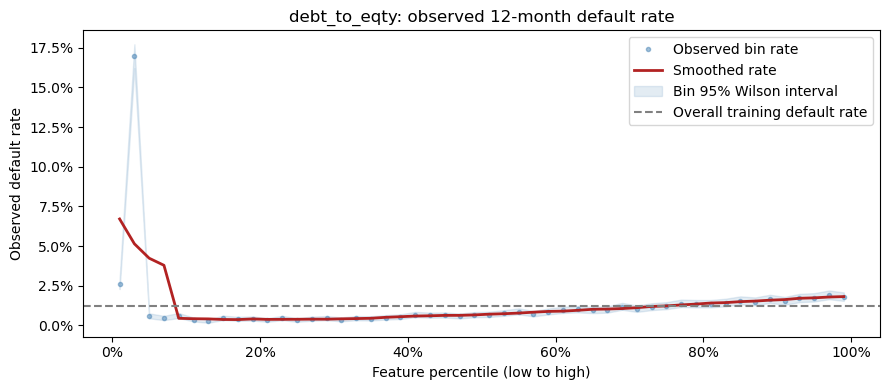

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,247,-223103.0714,-3.444240e+01,-136.4622,0.0259,0.01,0.0671,0.0229,0.0293
1,9524,1614,-34.4342,1.200000e-03,-9.1539,0.1695,0.03,0.0515,0.1621,0.1771
2,9523,56,0.0012,4.020000e-02,0.0181,0.0059,0.05,0.0424,0.0045,0.0076
3,9524,43,0.0402,1.166000e-01,0.0755,0.0045,0.07,0.0379,0.0034,0.0061
4,9524,58,0.1166,2.045000e-01,0.1603,0.0061,0.09,0.0045,0.0047,0.0079
5,9523,34,0.2045,2.952000e-01,0.2501,0.0036,0.11,0.0043,0.0026,0.0050
6,9524,24,0.2953,3.901000e-01,0.3422,0.0025,0.13,0.0042,0.0017,0.0037
7,9524,44,0.3901,4.873000e-01,0.4382,0.0046,0.15,0.0038,0.0034,0.0062
8,9523,38,0.4873,5.864000e-01,0.5361,0.0040,0.17,0.0037,0.0029,0.0055
9,9524,40,0.5864,6.909000e-01,0.6377,0.0042,0.19,0.0041,0.0031,0.0057


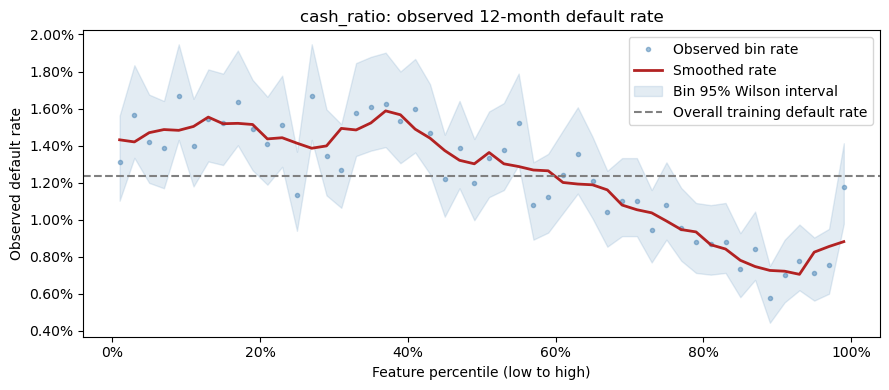

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,125,-1.3786,0.0000,0.0000,0.0131,0.01,0.0143,0.0110,0.0156
1,9524,149,0.0000,0.0000,0.0000,0.0156,0.03,0.0142,0.0133,0.0183
2,9523,135,0.0000,0.0001,0.0001,0.0142,0.05,0.0147,0.0120,0.0168
3,9524,132,0.0001,0.0001,0.0001,0.0139,0.07,0.0149,0.0117,0.0164
4,9524,159,0.0001,0.0002,0.0002,0.0167,0.09,0.0148,0.0143,0.0195
5,9523,133,0.0002,0.0003,0.0003,0.0140,0.11,0.0150,0.0118,0.0165
6,9524,147,0.0003,0.0004,0.0004,0.0154,0.13,0.0155,0.0131,0.0181
7,9524,145,0.0004,0.0006,0.0005,0.0152,0.15,0.0152,0.0130,0.0179
8,9523,156,0.0006,0.0008,0.0007,0.0164,0.17,0.0152,0.0140,0.0191
9,9524,142,0.0008,0.0010,0.0009,0.0149,0.19,0.0151,0.0127,0.0175


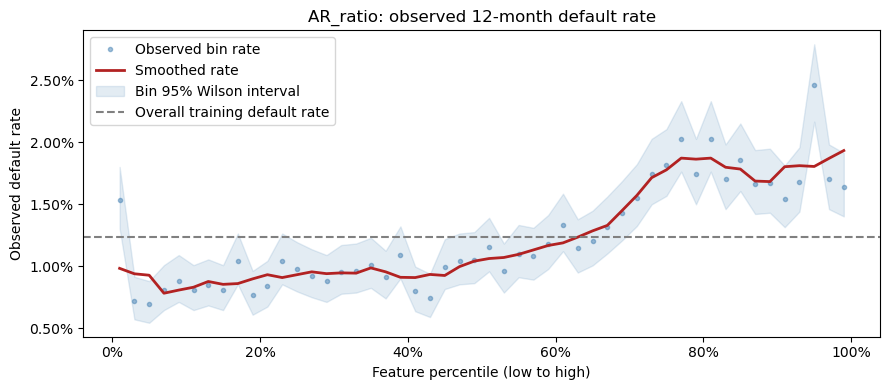

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,146,-1.904954e+07,1.750000e-02,0.0057,0.0153,0.01,0.0098,0.0131,0.0180
1,9524,69,1.750000e-02,3.830000e-02,0.0284,0.0072,0.03,0.0094,0.0057,0.0092
2,9523,66,3.830000e-02,5.660000e-02,0.0476,0.0069,0.05,0.0093,0.0055,0.0088
3,9524,77,5.660000e-02,7.430000e-02,0.0654,0.0081,0.07,0.0078,0.0065,0.0101
4,9524,84,7.430000e-02,9.240000e-02,0.0832,0.0088,0.09,0.0081,0.0071,0.0109
5,9523,77,9.240000e-02,1.107000e-01,0.1014,0.0081,0.11,0.0083,0.0065,0.0101
6,9524,81,1.107000e-01,1.298000e-01,0.1202,0.0085,0.13,0.0088,0.0068,0.0106
7,9524,77,1.298000e-01,1.490000e-01,0.1395,0.0081,0.15,0.0085,0.0065,0.0101
8,9523,99,1.490000e-01,1.680000e-01,0.1586,0.0104,0.17,0.0086,0.0085,0.0126
9,9524,73,1.680000e-01,1.864000e-01,0.1771,0.0077,0.19,0.0090,0.0061,0.0096


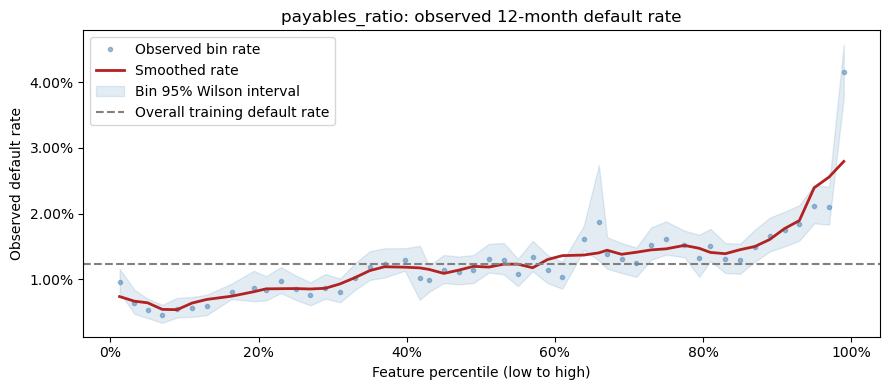

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,11742,113,-3.5836,0.0000,0.0000,0.0096,0.0123,0.0074,0.0080,0.0116
1,7306,46,0.0000,0.0004,0.0002,0.0063,0.0323,0.0066,0.0047,0.0084
2,9523,51,0.0004,0.0012,0.0008,0.0054,0.0500,0.0064,0.0041,0.0070
3,9524,43,0.0012,0.0023,0.0017,0.0045,0.0700,0.0054,0.0034,0.0061
4,9524,52,0.0023,0.0039,0.0030,0.0055,0.0900,0.0054,0.0042,0.0072
5,9523,53,0.0039,0.0059,0.0048,0.0056,0.1100,0.0064,0.0043,0.0073
6,9524,56,0.0059,0.0088,0.0073,0.0059,0.1300,0.0069,0.0045,0.0076
7,22329,180,0.0088,0.0121,0.0121,0.0081,0.1634,0.0074,0.0070,0.0093
8,6242,54,0.0121,0.0145,0.0130,0.0087,0.1934,0.0081,0.0066,0.0113
9,9524,80,0.0145,0.0197,0.0169,0.0084,0.2100,0.0085,0.0068,0.0104


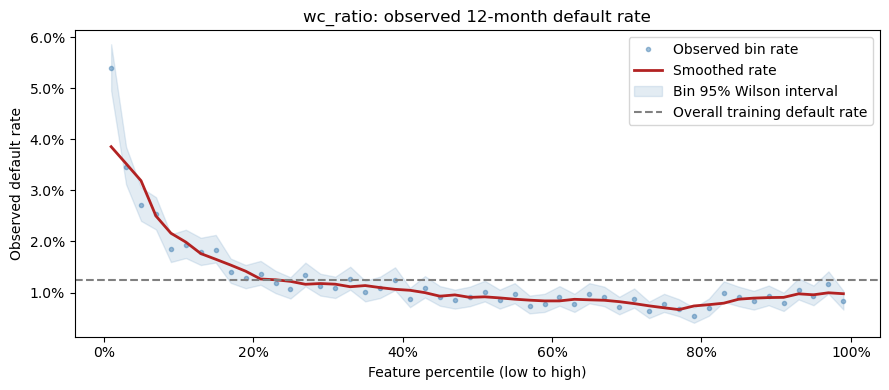

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,513,-56.1449,-0.6293,-0.8081,0.0539,0.01,0.0385,0.0495,0.0586
1,9524,330,-0.6293,-0.4236,-0.5083,0.0346,0.03,0.0352,0.0312,0.0385
2,9523,258,-0.4236,-0.3140,-0.3609,0.0271,0.05,0.0319,0.0240,0.0305
3,9524,241,-0.3140,-0.2452,-0.2760,0.0253,0.07,0.0250,0.0223,0.0287
4,9524,176,-0.2452,-0.1960,-0.2185,0.0185,0.09,0.0216,0.0160,0.0214
5,9523,184,-0.1960,-0.1587,-0.1765,0.0193,0.11,0.0199,0.0167,0.0223
6,9524,170,-0.1587,-0.1284,-0.1428,0.0178,0.13,0.0176,0.0154,0.0207
7,9524,175,-0.1284,-0.1038,-0.1156,0.0184,0.15,0.0165,0.0159,0.0213
8,9523,134,-0.1038,-0.0829,-0.0929,0.0141,0.17,0.0154,0.0119,0.0166
9,9524,123,-0.0829,-0.0643,-0.0731,0.0129,0.19,0.0142,0.0108,0.0154


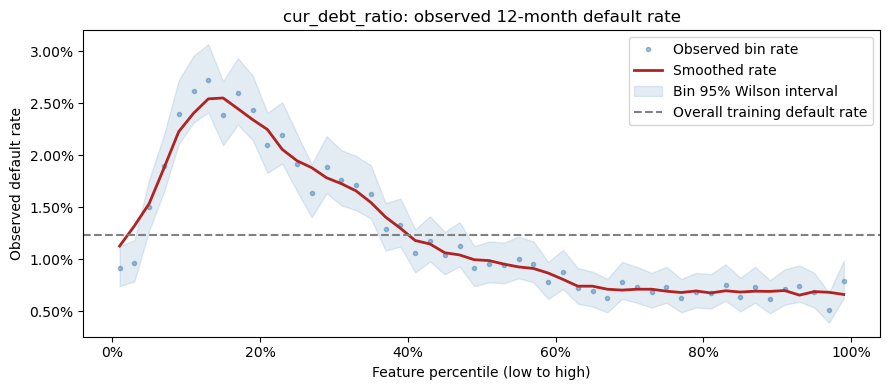

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,87,-2.201323e+06,6.690000e-02,0.0285,0.0091,0.01,0.0113,0.0074,0.0113
1,9524,92,6.700000e-02,1.480000e-01,0.1072,0.0097,0.03,0.0132,0.0079,0.0118
2,9523,143,1.480000e-01,2.404000e-01,0.1922,0.0150,0.05,0.0154,0.0128,0.0177
3,9524,181,2.404000e-01,3.431000e-01,0.2909,0.0190,0.07,0.0188,0.0164,0.0219
4,9524,228,3.431000e-01,4.513000e-01,0.3969,0.0239,0.09,0.0223,0.0211,0.0272
5,9523,249,4.513000e-01,5.526000e-01,0.5030,0.0261,0.11,0.0240,0.0231,0.0295
6,9524,259,5.526000e-01,6.422000e-01,0.6003,0.0272,0.13,0.0254,0.0241,0.0307
7,9524,227,6.423000e-01,7.178000e-01,0.6813,0.0238,0.15,0.0255,0.0210,0.0271
8,9523,247,7.178000e-01,7.803000e-01,0.7503,0.0259,0.17,0.0245,0.0229,0.0293
9,9524,232,7.803000e-01,8.331000e-01,0.8079,0.0244,0.19,0.0234,0.0214,0.0277


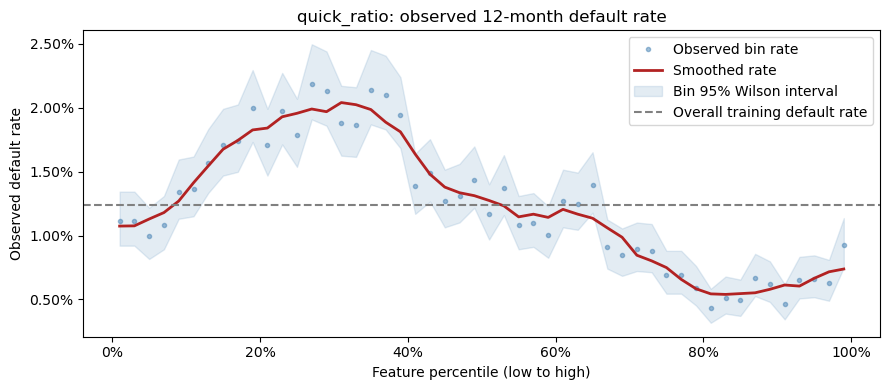

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,106,-986328.0000,2.200000e-02,0.0100,0.0111,0.01,0.0107,0.0092,0.0134
1,9524,106,0.0220,4.610000e-02,0.0341,0.0111,0.03,0.0108,0.0092,0.0134
2,9523,95,0.0461,7.040000e-02,0.0581,0.0100,0.05,0.0113,0.0082,0.0122
3,9524,103,0.0704,9.540000e-02,0.0829,0.0108,0.07,0.0118,0.0089,0.0131
4,9524,128,0.0954,1.219000e-01,0.1085,0.0134,0.09,0.0127,0.0113,0.0160
5,9523,130,0.1219,1.491000e-01,0.1353,0.0137,0.11,0.0141,0.0115,0.0162
6,9524,149,0.1491,1.776000e-01,0.1632,0.0156,0.13,0.0155,0.0133,0.0183
7,9524,163,0.1776,2.090000e-01,0.1929,0.0171,0.15,0.0168,0.0147,0.0199
8,9523,166,0.2090,2.421000e-01,0.2255,0.0174,0.17,0.0175,0.0150,0.0203
9,9524,190,0.2421,2.767000e-01,0.2593,0.0199,0.19,0.0183,0.0173,0.0230


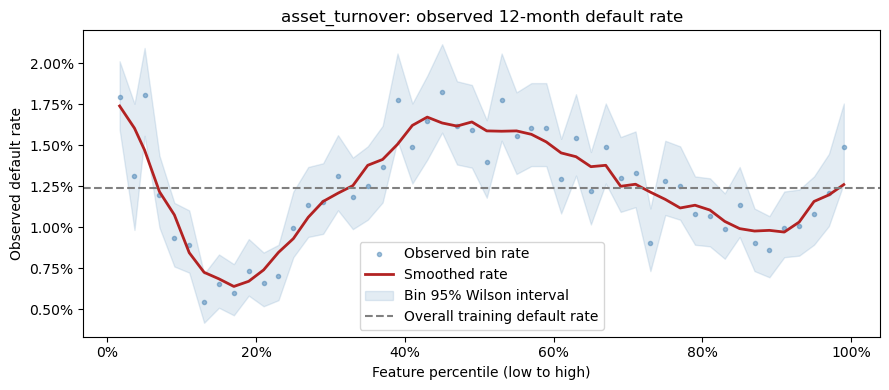

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,15622,280,-2.0939,0.0000,0.0000,0.0179,0.0164,0.0174,0.0160,0.0201
1,3426,45,0.0000,0.0002,0.0000,0.0131,0.0364,0.0160,0.0098,0.0175
2,9523,172,0.0002,0.0081,0.0029,0.0181,0.0500,0.0147,0.0156,0.0209
3,9524,114,0.0081,0.0200,0.0141,0.0120,0.0700,0.0122,0.0100,0.0144
4,9524,89,0.0200,0.0310,0.0256,0.0093,0.0900,0.0108,0.0076,0.0115
5,9523,85,0.0310,0.0412,0.0362,0.0089,0.1100,0.0084,0.0072,0.0110
6,9524,52,0.0412,0.0512,0.0462,0.0055,0.1300,0.0072,0.0042,0.0072
7,9524,62,0.0512,0.0617,0.0563,0.0065,0.1500,0.0068,0.0051,0.0083
8,9523,57,0.0617,0.0734,0.0673,0.0060,0.1700,0.0064,0.0046,0.0077
9,9524,70,0.0734,0.0869,0.0798,0.0073,0.1900,0.0067,0.0058,0.0093


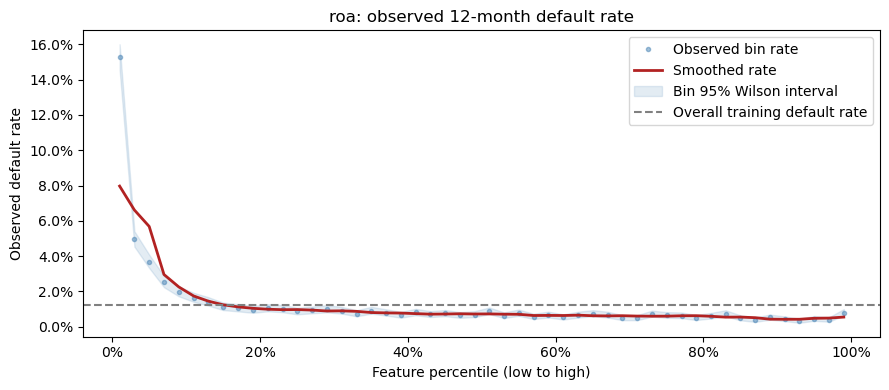

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9528,1455,-130738.6503,-13.13,-21.485,0.1527,0.0100,0.0797,0.1456,0.1601
1,9524,472,-13.1200,-7.16,-9.350,0.0496,0.0300,0.0661,0.0454,0.0541
2,9545,352,-7.1500,-4.49,-5.600,0.0369,0.0500,0.0568,0.0333,0.0408
3,9506,241,-4.4800,-3.00,-3.640,0.0254,0.0700,0.0296,0.0224,0.0287
4,9585,190,-2.9900,-2.01,-2.440,0.0198,0.0901,0.0225,0.0172,0.0228
5,9597,158,-2.0000,-1.35,-1.650,0.0165,0.1102,0.0174,0.0141,0.0192
6,9406,133,-1.3400,-0.89,-1.090,0.0141,0.1302,0.0145,0.0119,0.0167
7,9614,109,-0.8800,-0.56,-0.710,0.0113,0.1501,0.0124,0.0094,0.0137
8,9560,101,-0.5500,-0.32,-0.430,0.0106,0.1703,0.0112,0.0087,0.0128
9,9544,92,-0.3100,-0.14,-0.220,0.0096,0.1903,0.0104,0.0079,0.0118


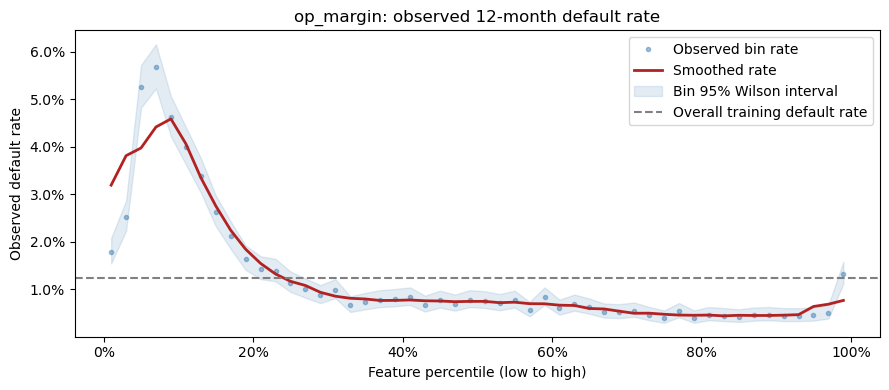

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,171,-3.086207e+07,-7.199000e+03,-25167.0000,0.0180,0.01,0.0319,0.0155,0.0208
1,9524,241,-7.197000e+03,-5.445300e+00,-609.5000,0.0253,0.03,0.0381,0.0223,0.0287
2,9523,500,-5.445200e+00,-8.869000e-01,-1.6794,0.0525,0.05,0.0397,0.0482,0.0572
3,9524,540,-8.867000e-01,-3.823000e-01,-0.5603,0.0567,0.07,0.0441,0.0522,0.0615
4,9524,440,-3.822000e-01,-2.053000e-01,-0.2760,0.0462,0.09,0.0458,0.0422,0.0506
5,9523,381,-2.053000e-01,-1.183000e-01,-0.1555,0.0400,0.11,0.0406,0.0363,0.0441
6,9524,322,-1.183000e-01,-6.930000e-02,-0.0906,0.0338,0.13,0.0335,0.0304,0.0376
7,9524,251,-6.930000e-02,-3.970000e-02,-0.0527,0.0264,0.15,0.0276,0.0233,0.0298
8,9523,202,-3.970000e-02,-2.030000e-02,-0.0290,0.0212,0.17,0.0224,0.0185,0.0243
9,9524,157,-2.030000e-02,-7.900000e-03,-0.0134,0.0165,0.19,0.0185,0.0141,0.0192


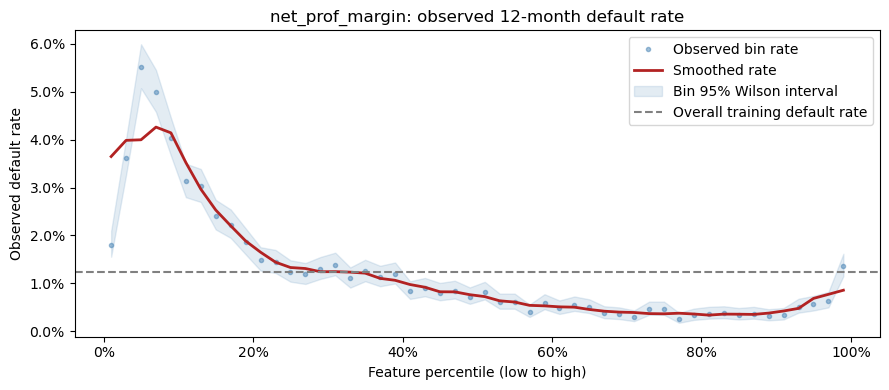

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,172,-4.593282e+08,-5.282000e+03,-29236.5000,0.0181,0.01,0.0365,0.0156,0.0209
1,9524,345,-5.280000e+03,-3.529500e+00,-34.2154,0.0362,0.03,0.0398,0.0327,0.0402
2,9523,525,-3.525500e+00,-8.708000e-01,-1.4833,0.0551,0.05,0.0400,0.0507,0.0599
3,9524,476,-8.707000e-01,-4.360000e-01,-0.5963,0.0500,0.07,0.0426,0.0458,0.0545
4,9524,385,-4.360000e-01,-2.635000e-01,-0.3343,0.0404,0.09,0.0414,0.0367,0.0446
5,9523,298,-2.635000e-01,-1.731000e-01,-0.2121,0.0313,0.11,0.0352,0.0280,0.0350
6,9524,288,-1.731000e-01,-1.187000e-01,-0.1425,0.0302,0.13,0.0297,0.0270,0.0339
7,9524,230,-1.187000e-01,-8.400000e-02,-0.0995,0.0241,0.15,0.0253,0.0213,0.0274
8,9523,212,-8.400000e-02,-6.010000e-02,-0.0710,0.0223,0.17,0.0220,0.0195,0.0254
9,9524,177,-6.010000e-02,-4.350000e-02,-0.0512,0.0186,0.19,0.0189,0.0161,0.0215


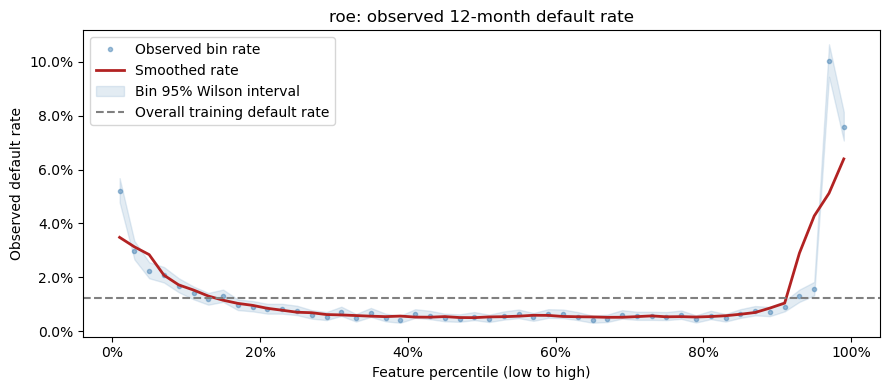

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,497,-2.001345e+09,-2.480375e+02,-507.1651,0.0522,0.01,0.0349,0.0479,0.0568
1,9524,285,-2.480025e+02,-1.103735e+02,-156.7043,0.0299,0.03,0.0313,0.0267,0.0335
2,9523,214,-1.103727e+02,-6.262160e+01,-81.6618,0.0225,0.05,0.0285,0.0197,0.0256
3,9524,198,-6.262120e+01,-4.038590e+01,-49.4525,0.0208,0.07,0.0208,0.0181,0.0239
4,9524,161,-4.038520e+01,-2.780790e+01,-33.2087,0.0169,0.09,0.0172,0.0145,0.0197
5,9523,134,-2.780730e+01,-1.990410e+01,-23.4703,0.0141,0.11,0.0153,0.0119,0.0166
6,9524,113,-1.990110e+01,-1.444450e+01,-16.8972,0.0119,0.13,0.0131,0.0099,0.0142
7,9524,124,-1.444360e+01,-1.055460e+01,-12.3169,0.0130,0.15,0.0116,0.0109,0.0155
8,9523,92,-1.055390e+01,-7.662300e+00,-9.0014,0.0097,0.17,0.0104,0.0079,0.0118
9,9524,87,-7.662200e+00,-5.504800e+00,-6.5210,0.0091,0.19,0.0096,0.0074,0.0113


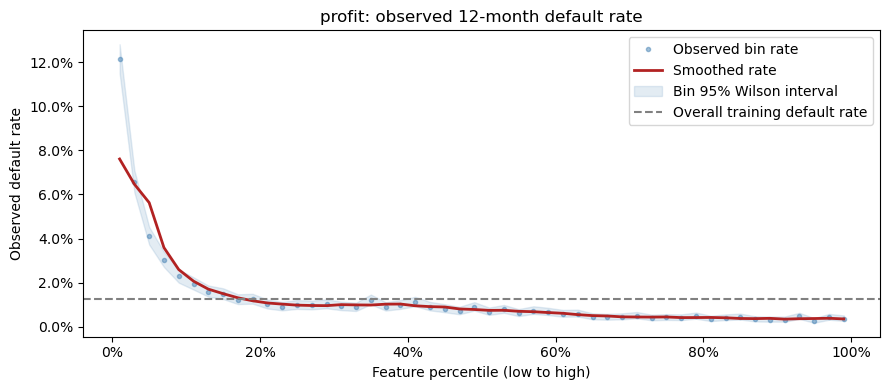

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,1156,-1.234770e+09,-1.101066e+06,-2269422.0,0.1214,0.01,0.0761,0.1150,0.1281
1,9524,626,-1.100938e+06,-4.983670e+05,-703056.0,0.0657,0.03,0.0646,0.0609,0.0709
2,9523,391,-4.983390e+05,-3.044770e+05,-382266.0,0.0411,0.05,0.0563,0.0373,0.0452
3,9524,289,-3.044650e+05,-2.088930e+05,-251537.5,0.0303,0.07,0.0359,0.0271,0.0340
4,9524,217,-2.088810e+05,-1.523980e+05,-177735.5,0.0228,0.09,0.0259,0.0200,0.0260
5,9523,185,-1.523830e+05,-1.124560e+05,-130275.0,0.0194,0.11,0.0207,0.0168,0.0224
6,9524,152,-1.124540e+05,-8.596800e+04,-97992.0,0.0160,0.13,0.0171,0.0136,0.0187
7,9525,141,-8.596300e+04,-6.606700e+04,-75243.0,0.0148,0.15,0.0150,0.0126,0.0174
8,9522,117,-6.605900e+04,-5.090500e+04,-57979.5,0.0123,0.17,0.0131,0.0103,0.0147
9,9526,119,-5.090400e+04,-3.937900e+04,-44823.5,0.0125,0.19,0.0118,0.0105,0.0149


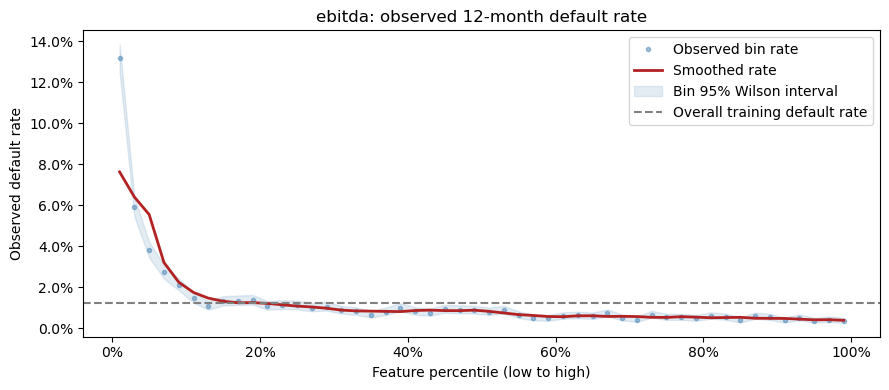

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,1253,-5.435868e+09,-4.930690e+05,-1035022.0,0.1316,0.0100,0.0762,0.1249,0.1385
1,9525,562,-4.930560e+05,-1.997390e+05,-298347.0,0.0590,0.0300,0.0640,0.0544,0.0639
2,9522,363,-1.997250e+05,-9.941100e+04,-139783.5,0.0381,0.0500,0.0554,0.0345,0.0422
3,9524,260,-9.940600e+04,-5.023100e+04,-70542.5,0.0273,0.0700,0.0321,0.0242,0.0308
4,9526,202,-5.022700e+04,-2.519900e+04,-35990.5,0.0212,0.0900,0.0224,0.0185,0.0243
5,9522,140,-2.519800e+04,-1.177000e+04,-17477.0,0.0147,0.1100,0.0175,0.0125,0.0173
6,9524,104,-1.176900e+04,-4.111000e+03,-7475.5,0.0109,0.1300,0.0147,0.0090,0.0132
7,9524,125,-4.110000e+03,2.667000e+03,-1078.5,0.0131,0.1500,0.0132,0.0110,0.0156
8,9522,128,2.668000e+03,1.450300e+04,8576.0,0.0134,0.1700,0.0124,0.0113,0.0160
9,9524,130,1.450500e+04,2.524800e+04,19987.0,0.0136,0.1900,0.0125,0.0115,0.0162


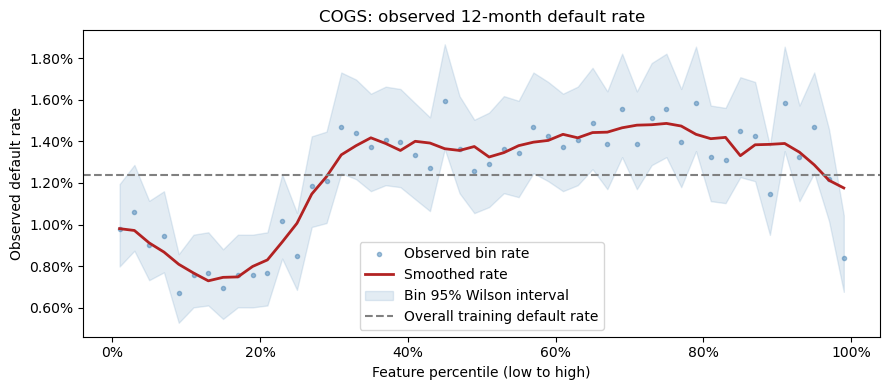

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,93,-14513767.0,6.097000e+03,785.5,0.0098,0.01,0.0098,0.0080,0.0119
1,9524,101,6101.0,1.971100e+04,12269.0,0.0106,0.03,0.0097,0.0087,0.0129
2,9523,86,19714.0,3.864400e+04,28747.0,0.0090,0.05,0.0091,0.0073,0.0111
3,9524,90,38646.0,5.985400e+04,48952.0,0.0094,0.07,0.0087,0.0077,0.0116
4,9524,64,59855.0,8.317600e+04,70997.5,0.0067,0.09,0.0081,0.0053,0.0086
5,9523,72,83177.0,1.097040e+05,95691.0,0.0076,0.11,0.0077,0.0060,0.0095
6,9524,73,109706.0,1.420160e+05,125061.0,0.0077,0.13,0.0073,0.0061,0.0096
7,9524,66,142017.0,1.810090e+05,160368.0,0.0069,0.15,0.0075,0.0055,0.0088
8,9523,72,181030.0,2.288870e+05,204182.0,0.0076,0.17,0.0075,0.0060,0.0095
9,9524,72,228901.0,2.874080e+05,256937.0,0.0076,0.19,0.0080,0.0060,0.0095


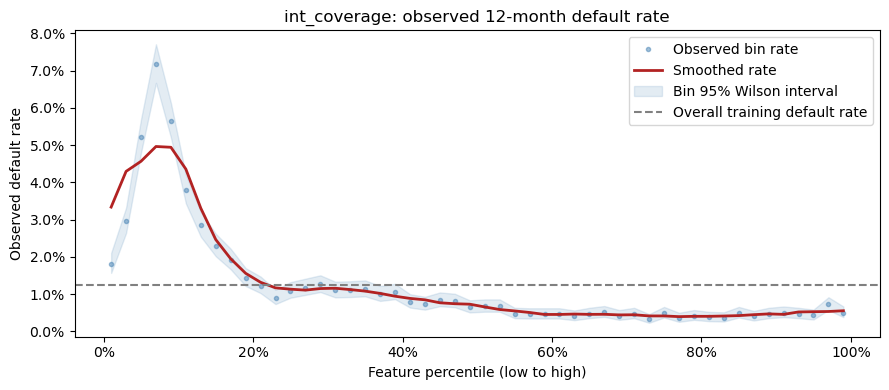

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,173,-1.572870e+09,-6.990000e+02,-7986.4172,0.0182,0.01,0.0334,0.0157,0.0210
1,9524,282,-6.987681e+02,-3.725930e+01,-112.8433,0.0296,0.03,0.0429,0.0264,0.0332
2,9523,498,-3.725680e+01,-9.372300e+00,-16.7903,0.0523,0.05,0.0457,0.0480,0.0569
3,9524,683,-9.372100e+00,-3.824000e+00,-5.7580,0.0717,0.07,0.0496,0.0667,0.0771
4,9524,538,-3.824000e+00,-1.780700e+00,-2.5942,0.0565,0.09,0.0494,0.0520,0.0613
5,9523,362,-1.780600e+00,-7.648000e-01,-1.1895,0.0380,0.11,0.0436,0.0344,0.0420
6,9524,272,-7.648000e-01,-2.288000e-01,-0.4569,0.0286,0.13,0.0331,0.0254,0.0321
7,9524,219,-2.287000e-01,8.920000e-02,-0.0604,0.0230,0.15,0.0246,0.0202,0.0262
8,9523,183,8.920000e-02,4.296000e-01,0.2728,0.0192,0.17,0.0195,0.0166,0.0222
9,9524,137,4.296000e-01,6.693000e-01,0.5583,0.0144,0.19,0.0156,0.0122,0.0170


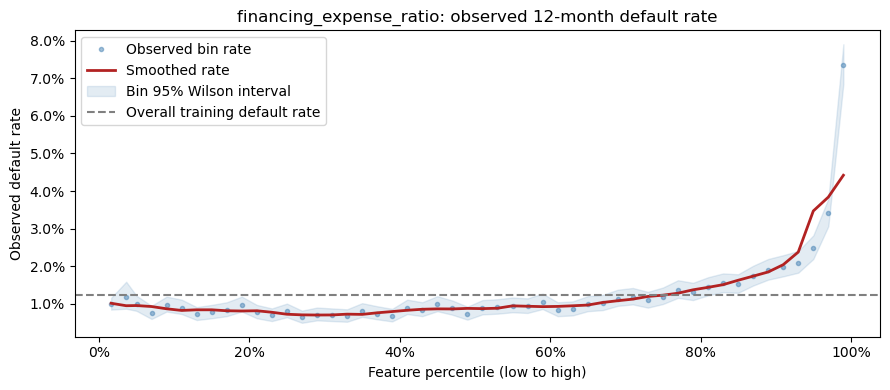

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,15486,154,-0.0512,0.0000,0.0000,0.0099,0.0163,0.0102,0.0085,0.0116
1,3562,42,0.0000,0.0000,0.0000,0.0118,0.0363,0.0095,0.0087,0.0159
2,9523,95,0.0000,0.0000,0.0000,0.0100,0.0500,0.0096,0.0082,0.0122
3,9524,72,0.0000,0.0001,0.0001,0.0076,0.0700,0.0093,0.0060,0.0095
4,9524,93,0.0001,0.0002,0.0001,0.0098,0.0900,0.0087,0.0080,0.0119
5,9523,86,0.0002,0.0004,0.0003,0.0090,0.1100,0.0083,0.0073,0.0111
6,9524,69,0.0004,0.0006,0.0005,0.0072,0.1300,0.0084,0.0057,0.0092
7,9524,74,0.0006,0.0009,0.0007,0.0078,0.1500,0.0084,0.0062,0.0097
8,9523,80,0.0009,0.0013,0.0011,0.0084,0.1700,0.0082,0.0068,0.0104
9,9524,93,0.0013,0.0018,0.0015,0.0098,0.1900,0.0081,0.0080,0.0119


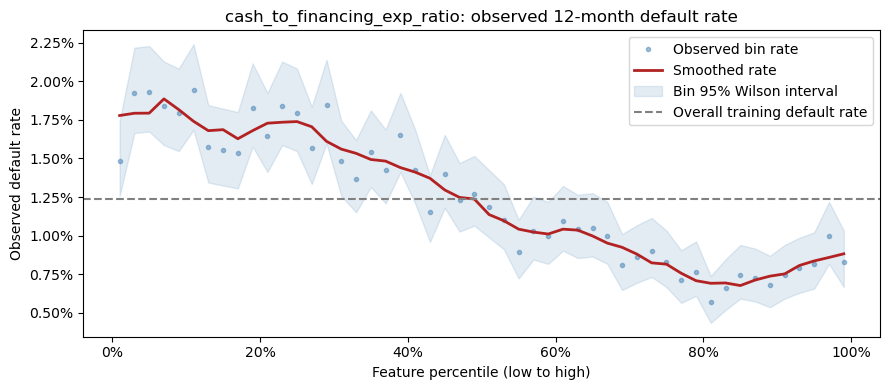

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,141,-2.682085e+06,2.000000e-04,0.0000,0.0148,0.01,0.0178,0.0126,0.0174
1,9524,183,2.000000e-04,1.900000e-03,0.0009,0.0192,0.03,0.0179,0.0166,0.0222
2,9523,184,1.900000e-03,4.700000e-03,0.0032,0.0193,0.05,0.0179,0.0167,0.0223
3,9524,175,4.700000e-03,8.700000e-03,0.0066,0.0184,0.07,0.0189,0.0159,0.0213
4,9524,171,8.700000e-03,1.390000e-02,0.0111,0.0180,0.09,0.0182,0.0155,0.0208
5,9523,185,1.390000e-02,2.060000e-02,0.0170,0.0194,0.11,0.0174,0.0168,0.0224
6,9524,150,2.060000e-02,2.910000e-02,0.0246,0.0157,0.13,0.0168,0.0134,0.0185
7,9524,148,2.910000e-02,3.960000e-02,0.0341,0.0155,0.15,0.0169,0.0132,0.0182
8,9523,146,3.960000e-02,5.260000e-02,0.0459,0.0153,0.17,0.0163,0.0131,0.0180
9,9524,174,5.260000e-02,6.870000e-02,0.0603,0.0183,0.19,0.0168,0.0158,0.0212


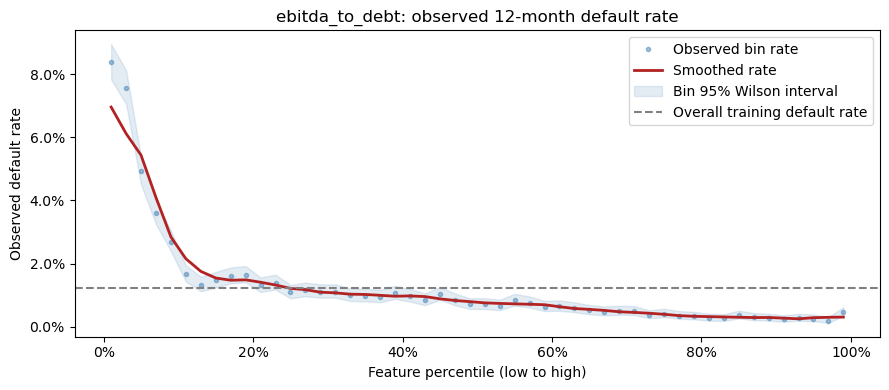

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,797,-955383.0000,-2.253000e-01,-0.4823,0.0837,0.01,0.0695,0.0783,0.0894
1,9524,721,-0.2253,-9.660000e-02,-0.1406,0.0757,0.03,0.0612,0.0706,0.0812
2,9523,469,-0.0966,-4.830000e-02,-0.0676,0.0492,0.05,0.0543,0.0451,0.0538
3,9524,343,-0.0483,-2.460000e-02,-0.0346,0.0360,0.07,0.0409,0.0325,0.0399
4,9524,257,-0.0246,-1.190000e-02,-0.0173,0.0270,0.09,0.0285,0.0239,0.0304
5,9523,159,-0.0119,-5.300000e-03,-0.0081,0.0167,0.11,0.0215,0.0143,0.0195
6,9524,127,-0.0053,-1.700000e-03,-0.0032,0.0133,0.13,0.0176,0.0112,0.0158
7,9524,140,-0.0017,1.100000e-03,-0.0004,0.0147,0.15,0.0155,0.0125,0.0173
8,9523,153,0.0011,6.300000e-03,0.0037,0.0161,0.17,0.0147,0.0137,0.0188
9,9524,157,0.0063,1.110000e-02,0.0087,0.0165,0.19,0.0149,0.0141,0.0192


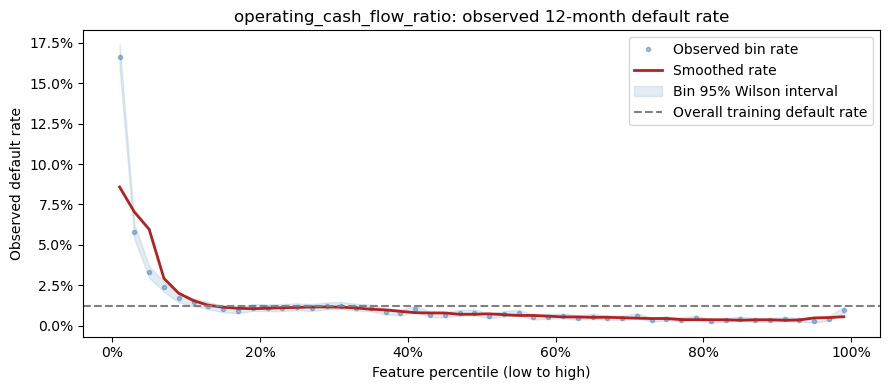

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,1586,-73.9841,-0.1085,-0.1890,0.1665,0.0100,0.0858,0.1592,0.1741
1,9524,551,-0.1085,-0.0557,-0.0746,0.0579,0.0300,0.0703,0.0533,0.0627
2,9523,314,-0.0557,-0.0348,-0.0435,0.0330,0.0500,0.0596,0.0296,0.0368
3,9524,226,-0.0348,-0.0231,-0.0282,0.0237,0.0700,0.0291,0.0209,0.0270
4,9524,160,-0.0231,-0.0155,-0.0188,0.0168,0.0900,0.0200,0.0144,0.0196
5,9523,137,-0.0155,-0.0104,-0.0127,0.0144,0.1100,0.0154,0.0122,0.0170
6,9524,115,-0.0104,-0.0070,-0.0086,0.0121,0.1300,0.0125,0.0101,0.0145
7,9524,97,-0.0070,-0.0047,-0.0058,0.0102,0.1500,0.0114,0.0084,0.0124
8,9523,88,-0.0047,-0.0028,-0.0037,0.0092,0.1700,0.0107,0.0075,0.0114
9,9524,105,-0.0028,-0.0013,-0.0020,0.0110,0.1900,0.0104,0.0091,0.0133


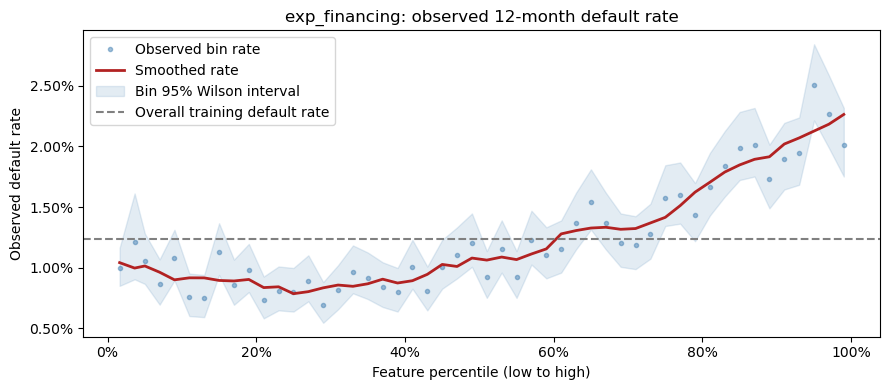

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,15486,154,-473788.0,0.000000e+00,0.0,0.0099,0.0163,0.0104,0.0085,0.0116
1,3725,45,1.0,8.000000e+00,3.0,0.0121,0.0364,0.0100,0.0090,0.0161
2,9397,99,9.0,1.100000e+02,43.0,0.0105,0.0502,0.0101,0.0087,0.0128
3,9514,82,111.0,3.140000e+02,201.0,0.0086,0.0701,0.0096,0.0069,0.0107
4,9504,103,315.0,6.630000e+02,464.0,0.0108,0.0900,0.0090,0.0089,0.0131
5,9522,72,664.0,1.258000e+03,926.0,0.0076,0.1100,0.0092,0.0060,0.0095
6,9518,71,1259.0,2.128000e+03,1656.0,0.0075,0.1300,0.0092,0.0059,0.0094
7,9528,108,2129.0,3.301000e+03,2673.5,0.0113,0.1500,0.0089,0.0094,0.0137
8,9532,82,3302.0,4.735000e+03,3990.0,0.0086,0.1700,0.0089,0.0069,0.0107
9,9512,93,4736.0,6.420000e+03,5562.0,0.0098,0.1900,0.0090,0.0080,0.0120


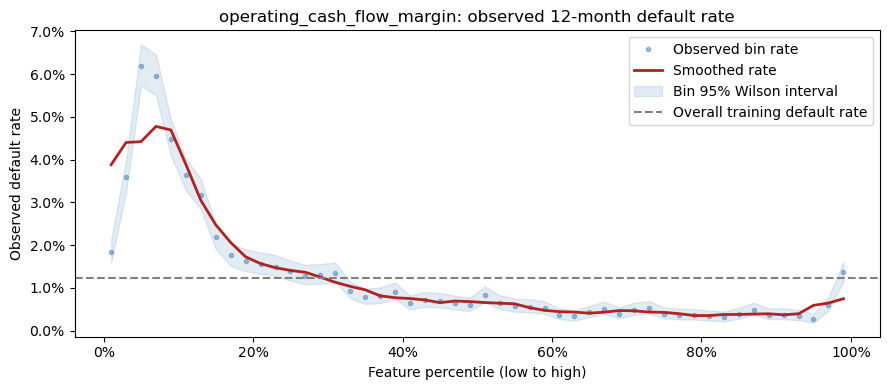

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,176,-4.593278e+08,-4.436667e+03,-26406.0000,0.0185,0.0100,0.0388,0.0160,0.0214
1,9524,343,-4.432000e+03,-2.716500e+00,-24.6413,0.0360,0.0300,0.0440,0.0325,0.0399
2,9523,590,-2.715900e+00,-5.935000e-01,-1.0718,0.0620,0.0500,0.0442,0.0573,0.0670
3,9524,568,-5.934000e-01,-2.576000e-01,-0.3777,0.0596,0.0700,0.0478,0.0551,0.0646
4,9524,428,-2.576000e-01,-1.363000e-01,-0.1841,0.0449,0.0900,0.0469,0.0410,0.0493
5,9523,346,-1.363000e-01,-7.720000e-02,-0.1024,0.0363,0.1100,0.0389,0.0328,0.0403
6,9524,303,-7.720000e-02,-4.430000e-02,-0.0584,0.0318,0.1300,0.0305,0.0285,0.0355
7,9524,208,-4.430000e-02,-2.480000e-02,-0.0334,0.0218,0.1500,0.0248,0.0191,0.0250
8,9523,168,-2.480000e-02,-1.280000e-02,-0.0181,0.0176,0.1700,0.0206,0.0152,0.0205
9,9524,155,-1.280000e-02,-5.000000e-03,-0.0084,0.0163,0.1900,0.0173,0.0139,0.0190


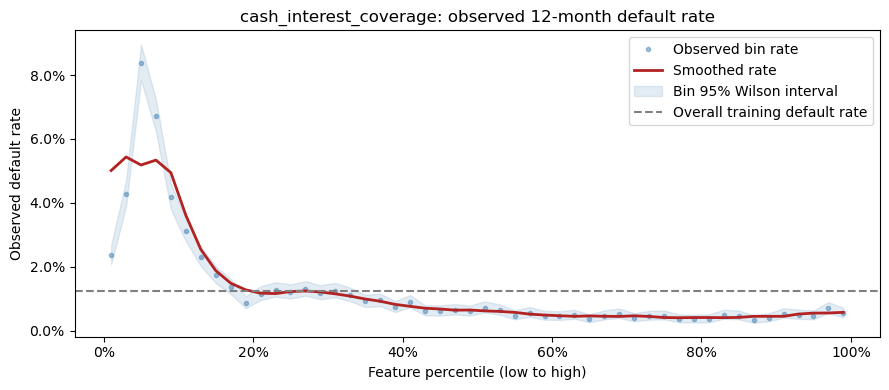

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,225,-1.971912e+08,-2.783529e+02,-4420.0000,0.0236,0.01,0.0501,0.0208,0.0269
1,9524,408,-2.782197e+02,-1.947710e+01,-52.1228,0.0428,0.03,0.0544,0.0390,0.0471
2,9523,799,-1.946910e+01,-6.355600e+00,-10.2895,0.0839,0.05,0.0518,0.0785,0.0896
3,9524,639,-6.354500e+00,-3.054900e+00,-4.2904,0.0671,0.07,0.0534,0.0622,0.0723
4,9524,398,-3.054700e+00,-1.745700e+00,-2.2851,0.0418,0.09,0.0494,0.0380,0.0460
5,9523,298,-1.745700e+00,-1.115100e+00,-1.3820,0.0313,0.11,0.0361,0.0280,0.0350
6,9524,220,-1.115100e+00,-7.076000e-01,-0.9038,0.0231,0.13,0.0254,0.0203,0.0263
7,9524,165,-7.075000e-01,-4.147000e-01,-0.5471,0.0173,0.15,0.0188,0.0149,0.0201
8,9523,130,-4.147000e-01,-2.228000e-01,-0.3081,0.0137,0.17,0.0149,0.0115,0.0162
9,9524,83,-2.227000e-01,-1.035000e-01,-0.1566,0.0087,0.19,0.0128,0.0070,0.0108


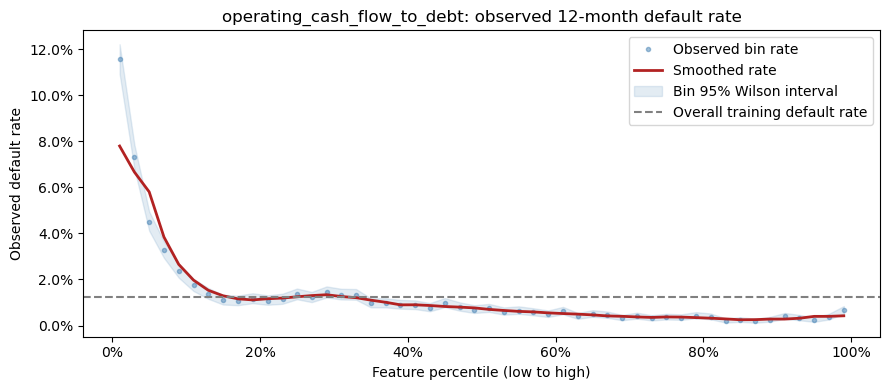

,n,defaults,value_min,value_max,value_median,default_rate,percentile,smooth_rate,ci_low,ci_high
0,9524,1100,-989812.0000,-2.081000e-01,-0.4060,0.1155,0.0100,0.0779,0.1092,0.1221
1,9524,696,-0.2081,-9.880000e-02,-0.1369,0.0731,0.0300,0.0666,0.0680,0.0785
2,9523,430,-0.0988,-5.840000e-02,-0.0743,0.0452,0.0500,0.0580,0.0412,0.0495
3,9524,312,-0.0584,-3.720000e-02,-0.0464,0.0328,0.0700,0.0384,0.0294,0.0365
4,9524,225,-0.0372,-2.430000e-02,-0.0301,0.0236,0.0900,0.0265,0.0208,0.0269
5,9523,166,-0.0243,-1.560000e-02,-0.0195,0.0174,0.1100,0.0197,0.0150,0.0203
6,9524,131,-0.0156,-9.900000e-03,-0.0124,0.0138,0.1300,0.0153,0.0116,0.0163
7,9524,105,-0.0099,-6.300000e-03,-0.0079,0.0110,0.1500,0.0129,0.0091,0.0133
8,9523,102,-0.0063,-3.700000e-03,-0.0049,0.0107,0.1700,0.0116,0.0088,0.0130
9,9524,111,-0.0037,-1.700000e-03,-0.0026,0.0117,0.1900,0.0111,0.0097,0.0140


In [11]:
def bin_feature(frame, feature, n_bins=50, window=5):
    data = frame[[feature, 'label']].copy()
    data[feature] = pd.to_numeric(data[feature], errors='coerce').replace([np.inf, -np.inf], np.nan)
    data = data.dropna()
    if data.empty or data[feature].nunique() < 2:
        return pd.DataFrame()
    data['bin'] = pd.qcut(data[feature], q=n_bins, duplicates='drop')
    out = data.groupby('bin', observed=True).agg(n=(feature, 'size'), defaults=('label', 'sum'), value_min=(feature, 'min'), value_max=(feature, 'max'), value_median=(feature, 'median')).reset_index(drop=True)
    out['default_rate'] = out.defaults / out.n
    out['percentile'] = (out.n.cumsum() - out.n / 2) / out.n.sum()
    out['smooth_rate'] = out.defaults.rolling(window, center=True, min_periods=1).sum() / out.n.rolling(window, center=True, min_periods=1).sum()
    z = 1.96
    denom = 1 + z*z/out.n
    center = (out.default_rate + z*z/(2*out.n))/denom
    half = z*np.sqrt(out.default_rate*(1-out.default_rate)/out.n + z*z/(4*out.n**2))/denom
    out['ci_low'], out['ci_high'] = center-half, center+half
    return out

tables = {}
plotted = set()
for group, names in groups.items():
    for name in names:
        if name in plotted:
            continue
        if name not in features:
            print('Unavailable:', name); continue
        table = bin_feature(features, name, N_BINS, SMOOTH_WINDOW)
        if table.empty:
            print('No usable variation:', name); continue
        tables[(group, name)] = table
        plotted.add(name)
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.plot(table.percentile, table.default_rate, '.', color='steelblue', alpha=.5, label='Observed bin rate')
        ax.plot(table.percentile, table.smooth_rate, color='firebrick', linewidth=2, label='Smoothed rate')
        ax.fill_between(table.percentile, table.ci_low, table.ci_high, color='steelblue', alpha=.15, label='Bin 95% Wilson interval')
        ax.axhline(features.label.mean(), color='gray', linestyle='--', label='Overall training default rate')
        ax.set(title=f'{name}: observed 12-month default rate', xlabel='Feature percentile (low to high)', ylabel='Observed default rate')
        ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(); fig.tight_layout(); plt.show()
        display(table.round(4))
# Inspect an individual feature's raw bin counts, rates and intervals with:
# display(tables[('liquidity_activity', 'quick_ratio')])

## Binary flags: separate 0 versus 1 comparison
Binary flags have two meaningful states, so quantile curves are inappropriate. Compare counts, defaults and observed rates by state. Flags can reveal data-quality or denominator conditions, but rare states are noisy and a flag may duplicate information already captured by another feature. Associations are not causal; evaluate incremental value and stability separately.

,feature,state,records,defaults,default_rate
0,city_Basilicata,0,474075,5876,0.012395
1,city_Basilicata,1,2108,16,0.007590
2,city_Calabria,0,470061,5832,0.012407
3,city_Calabria,1,6122,60,0.009801
4,city_Campania,0,448496,5493,0.012248
...,...,...,...,...,...
79,zero_rev_operating,1,14540,209,0.014374
80,zero_total_debt,0,476038,5892,0.012377
81,zero_total_debt,1,145,0,0.000000
82,zero_wc_net,0,476174,5892,0.012374


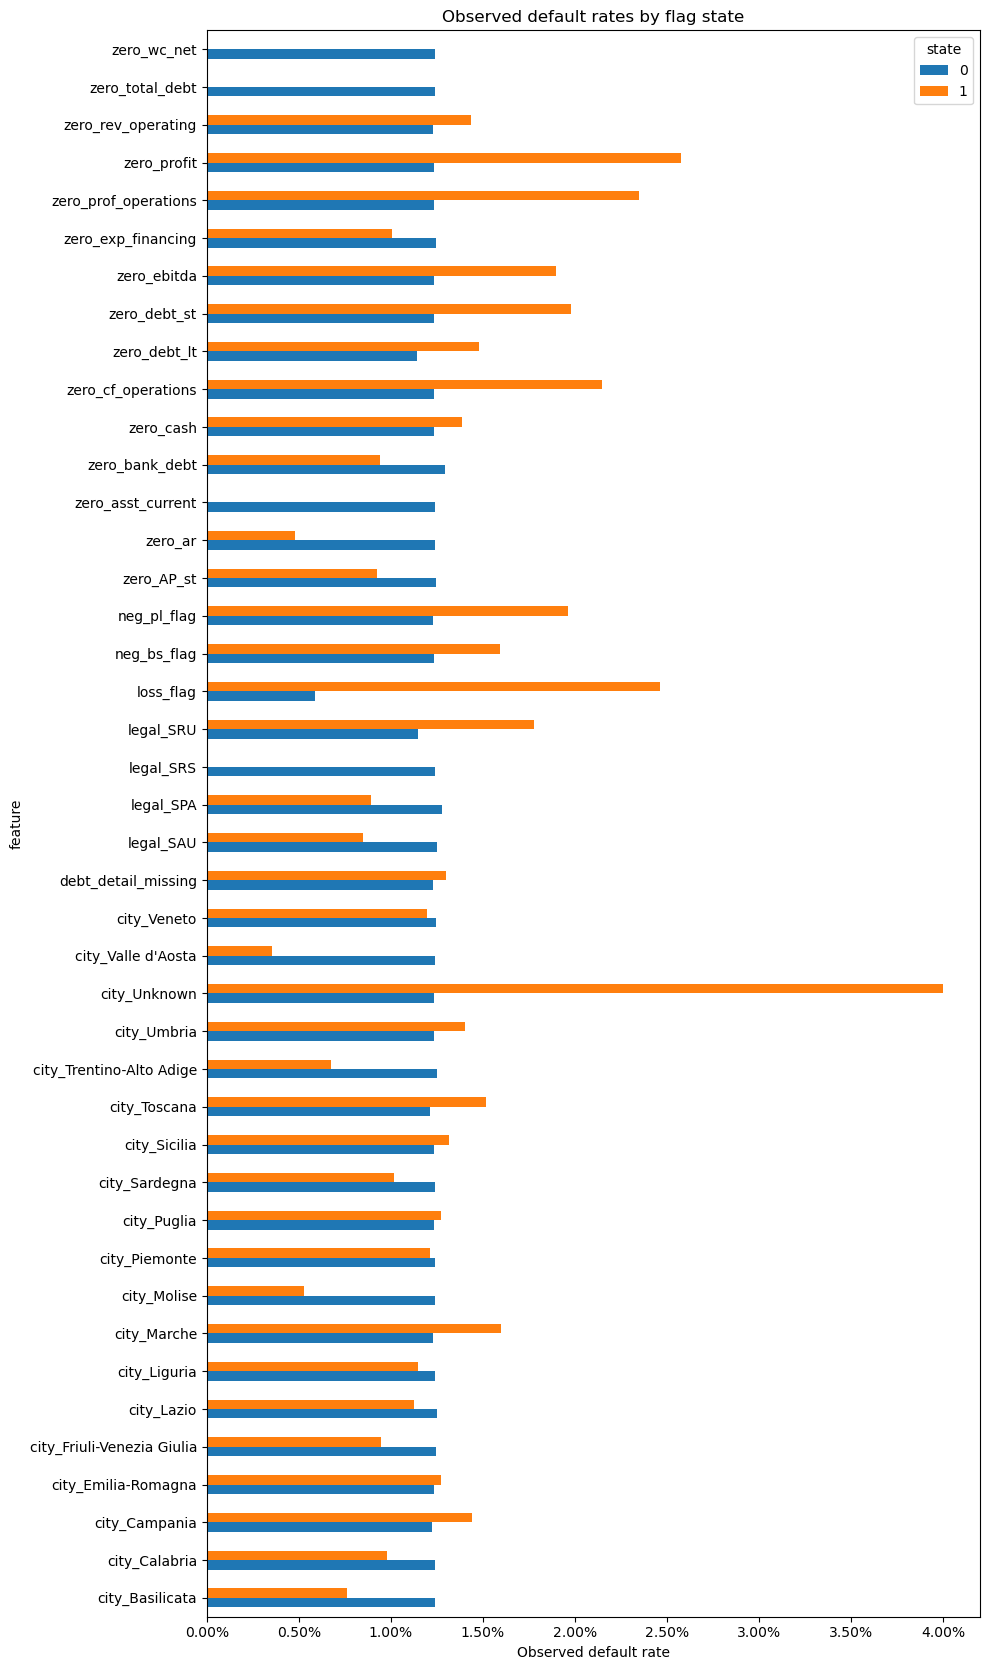

In [12]:
binary_features = [c for c in sorted(selected) if c in features and (c in active_schema['period_binary_features'] or c.startswith(('legal_', 'city_')))]
flag_results = []
for name in binary_features:
    tmp = features[[name, 'label']].dropna()
    for state in (0, 1):
        labels = tmp.loc[tmp[name] == state, 'label']
        flag_results.append({'feature': name, 'state': state, 'records': len(labels), 'defaults': int(labels.sum()), 'default_rate': labels.mean() if len(labels) else np.nan})
flags = pd.DataFrame(flag_results)
display(flags)
rates = flags.pivot(index='feature', columns='state', values='default_rate')
rates.plot.barh(figsize=(10, max(5, len(rates)*.4)), title='Observed default rates by flag state')
plt.gca().xaxis.set_major_formatter(PercentFormatter(1)); plt.xlabel('Observed default rate'); plt.tight_layout(); plt.show()